# Milestone 3 — Modeling, Evaluation & Error Analysis (Reference Matching)

**Nhóm:** Nhóm 11 — Nhập môn Khoa học Dữ liệu  
**Phạm vi báo cáo:** Huấn luyện mô hình xếp hạng ứng viên (`src/model/modeling.py`), điều phối toàn trình Milestone 3 (`src/model/run_matching.py`), đánh giá bằng chỉ số **MRR@5** tách riêng giữa tập nhãn thủ công (`manual`) và nhãn tự động (`auto`), phân tích độ quan trọng đặc trưng (**Permutation Importance** & **Ablation Study**), phân tích ca lỗi (**Error Analysis**) và kiểm chứng schema đầu ra `predictions.parquet`.

---

## 1. Tổng quan bài toán & Kiến trúc Modeling

### 1.1. Mô hình hóa bài toán Ranking
Với mỗi bài báo có $m$ mục BibTeX (từ Milestone 2) và $n$ tài liệu tham khảo có mã arXiv thu thập từ Semantic Scholar (từ Milestone 1), không gian ứng viên nội bộ bài báo tạo thành ma trận nhị phân $m \times n$:
- Mỗi dòng trong bảng đặc trưng (`candidate_matrix.parquet`) ứng với một cặp `(arxiv_id, citation_key, candidate_ref_id)` cùng **24 đặc trưng** chia làm 6 nhóm: `title` (8), `author` (5), `year` (3), `identifier` (2), `context` từ cây phân cấp M2 (3), và `relative` trong nhóm ứng viên (3).
- Các mô hình phân lớp điểm (*pointwise scorers*, thuần `scikit-learn`, **không sử dụng LLM hay mô hình pretrained**) dự đoán xác suất khớp $\hat{p}(i, j) \in [0, 1]$ cho từng ứng viên $j$, sau đó sắp xếp giảm dần để lấy **Top-5 ứng viên (`cand_1` đến `cand_5`)**.

### 1.2. Các mô hình, hậu xử lý và quy tắc chọn mô hình
| Thành phần | Chi tiết cài đặt trong `src/model/modeling.py` |
| :--- | :--- |
| **Mô hình so sánh (6 cấu hình)** | `heuristic_title` (baseline chỉ dựa trên `sim_title_ratio`), `logreg_C0.1`, `logreg_C1` (Logistic Regression chuẩn hóa `StandardScaler`, `class_weight='balanced'`), `hgb_lr0.1`, `hgb_lr0.05_d4` (`HistGradientBoostingClassifier`), `random_forest` (`RandomForestClassifier`). |
| **Hậu xử lý (3 chế độ)** | `none` (giữ nguyên thứ hạng mô hình); `id_override` (ưu tiên ứng viên khớp trực tiếp mã arXiv lên hạng 1); `id_override+one_to_one` (kết hợp gán một-một bằng thuật toán Hungarian `linear_sum_assignment` trong phạm vi từng bài báo). |
| **Quy tắc chọn mô hình** | Chọn tổ hợp `(model, postprocessing)` có **`MRR@5 (matchable)` cao nhất trên phần `manual` của tập `valid`** (đánh giá hoàn toàn trên mô hình chỉ học từ `train`, không refit vào `valid` để tránh rò rỉ dữ liệu). Tuyệt đối không chọn theo phần `auto` vì nhãn tự động được sinh bằng chính các độ đo tương đồng tiêu đề/tác giả nên có xu hướng cao giả tạo. |
| **Chỉ số đánh giá (MRR@5)** | $$\text{MRR@5} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}$$ Báo cáo song song hai góc nhìn: **`mrr@5`** (tính trên toàn bộ $|Q|$ entry đã gán nhãn, các entry không có bản arXiv tương ứng nhận điểm `0` theo đúng công thức đề) và **`mrr@5_matchable`** (chỉ tính trên các entry thực sự có tài liệu tham khảo arXiv đúng để đo năng lực xếp hạng thuần túy). |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "display" not in globals():
    try:
        from IPython.display import display
    except ImportError:
        display = print

plt.rcParams.update({
    "figure.autolayout": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

project_root = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
matching_dir = project_root / "data" / "matching"

metrics = json.loads((matching_dir / "metrics.json").read_text(encoding="utf-8"))
split_map = json.loads((matching_dir / "split.json").read_text(encoding="utf-8"))
comparison_df = pd.read_csv(matching_dir / "model_comparison.csv")
ablation_df = pd.read_csv(matching_dir / "ablation.csv")
importance_df = pd.read_csv(matching_dir / "feature_importance.csv")
labels_df = pd.read_csv(matching_dir / "labels.csv", dtype=str).fillna("")
preds_df = pd.read_parquet(matching_dir / "predictions.parquet")

print(f"Thư mục kết quả : {matching_dir.relative_to(project_root)}")
print(f"Tổng số bài báo : {metrics['publications_in_corpus']} (Manual: {metrics['manual_publications']}, Auto: {metrics['auto_publications']})")
print(f"Tổng cặp ứng viên: {metrics['candidate_pairs']:,} | Thời gian chạy pipeline: {metrics['elapsed_sec']}s")
print(f"Model được chọn : {metrics['selected_model']} + postprocessing='{metrics['selected_postprocessing']}'")

Thư mục kết quả : data\matching
Tổng số bài báo : 33 (Manual: 20, Auto: 13)
Tổng cặp ứng viên: 34,377 | Thời gian chạy pipeline: 89.52s
Model được chọn : logreg_C0.1 + postprocessing='id_override+one_to_one'


---

## 2. Thống kê Dữ liệu, Kiểm định Nhãn Tự động & Bảng Chia Tập

Toàn bộ **33/33 bài báo** hợp lệ trong corpus hiện có đều được sử dụng trọn vẹn (không bỏ sót bài nào):
- **20 bài gán nhãn thủ công (`manual`):** lấy 5 bài từ mỗi dải ID của 4 thành viên ($5k = 20$ bài, tổng 881 mục BibTeX đã được duyệt thủ công 100%).
- **13 bài còn lại ngoài tập thủ công (`auto`):** được gán nhãn tự động (`--auto-ratio 1.0`, vượt chuẩn tối thiểu $\ge 10\%$ và $\ge 2k = 8$ bài của đề).

Quy tắc chia tập cho nhóm $k = 4$ thành viên:
- **Tập Test:** $k = 4$ bài `manual` + $k = 4$ bài `auto` (**8 bài**, 364 entries).
- **Tập Validation:** $k = 4$ bài `manual` + $k = 4$ bài `auto` (**8 bài**, 364 entries).
- **Tập Training:** toàn bộ các bài còn lại (**12 bài `manual` + 5 bài `auto` = 17 bài**, 658 entries).

Ngoài ra, bộ `auto_labeler` được chạy đối chiếu chéo trên chính 20 bài gán nhãn thủ công của nhóm để kiểm chứng độ chính xác (`Precision / Recall`).

In [2]:
# 1. Bảng chia tập Train / Valid / Test tách theo nguồn nhãn (Manual vs Auto)
pub_to_part = {pid: part for part, pids in split_map.items() for pid in pids}
labels_with_part = labels_df.copy()
labels_with_part["partition"] = labels_with_part["arxiv_id"].map(pub_to_part)
labels_with_part = labels_with_part[labels_with_part["partition"].notna()].copy()
labels_with_part["has_match"] = labels_with_part["groundtruth_arxiv_id"].str.strip().ne("")

split_rows = []
for part in ("train", "valid", "test"):
    for src in ("manual", "auto", "all"):
        sub = labels_with_part[labels_with_part["partition"] == part]
        if src != "all":
            sub = sub[sub["label_source"] == src]
        n_pubs = sub["arxiv_id"].nunique()
        n_entries = len(sub)
        n_match = int(sub["has_match"].sum())
        match_rate = round(100.0 * n_match / n_entries, 2) if n_entries else 0.0
        split_rows.append({
            "Partition": part,
            "Label Source": src,
            "Publications": n_pubs,
            "BibTeX Entries (|Q|)": n_entries,
            "Matchable (Positive)": n_match,
            "Unmatched (Negative)": n_entries - n_match,
            "Match Rate (%)": match_rate,
        })

split_summary_df = pd.DataFrame(split_rows)
print("=== BẢNG CHIA TẬP DỮ LIỆU (TRAIN / VALID / TEST) ===")
display(split_summary_df)

# 2. Kiểm định chất lượng nhãn tự động trên 20 bài gán nhãn thủ công của nhóm
auto_val = metrics.get("auto_label_validation_on_manual_pool", {})
auto_val_df = pd.DataFrame([
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": k, "Giá trị": v}
    for k, v in auto_val.items()
])
print("\n=== KIỂM ĐỊNH ĐỘ TIN CẬY CỦA AUTO LABELER TRÊN POOL 20 BÀI MANUAL ===")
display(auto_val_df)

=== BẢNG CHIA TẬP DỮ LIỆU (TRAIN / VALID / TEST) ===

=== KIỂM ĐỊNH ĐỘ TIN CẬY CỦA AUTO LABELER TRÊN POOL 20 BÀI MANUAL ===


Partition,Label Source,Publications,BibTeX Entries (|Q|),Matchable (Positive),Unmatched (Negative),Match Rate (%)
train,manual,12,459,261,198,56.86
train,auto,5,199,67,132,33.67
train,all,17,658,328,330,49.85
valid,manual,4,178,102,76,57.30
valid,auto,4,186,55,131,29.57
valid,all,8,364,157,207,43.13
test,manual,4,244,90,154,36.89
test,auto,4,120,66,54,55.00
test,all,8,364,156,208,42.86


Chỉ số kiểm định Auto Labeler (trên 20 bài Manual),Giá trị
entries_compared,881.0000
auto_matches,428.0000
manual_matches,453.0000
precision,0.9977
recall,0.9426
no_match_agreement,0.9977
accuracy,0.9694


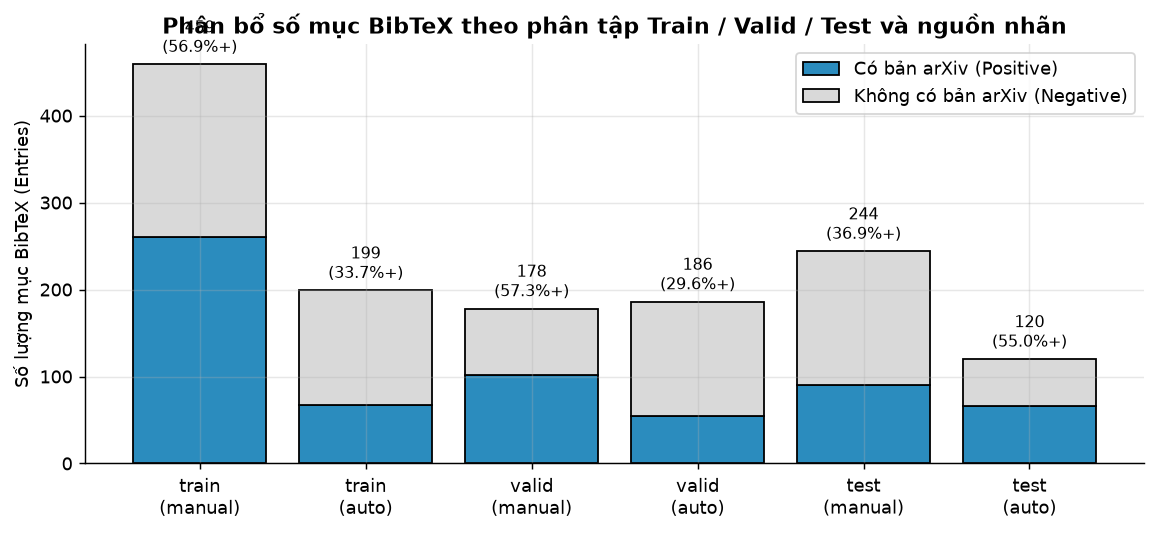

In [3]:
# Biểu đồ phân bổ entries (Positive vs Negative) theo Partition & Label Source
plot_df = split_summary_df[split_summary_df["Label Source"] != "all"].reset_index(drop=True)
plot_df["Group"] = plot_df["Partition"] + "\n(" + plot_df["Label Source"] + ")"

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["Matchable (Positive)"], label="Có bản arXiv (Positive)", color="#2b8cbe", edgecolor="black")
ax.bar(
    x,
    plot_df["Unmatched (Negative)"],
    bottom=plot_df["Matchable (Positive)"],
    label="Không có bản arXiv (Negative)",
    color="#d9d9d9",
    edgecolor="black",
)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Group"])
ax.set_ylabel("Số lượng mục BibTeX (Entries)")
ax.set_title("Phân bổ số mục BibTeX theo phân tập Train / Valid / Test và nguồn nhãn", fontweight="bold")
ax.legend()

for idx, row in plot_df.iterrows():
    total = int(row["BibTeX Entries (|Q|)"])
    rate = float(row["Match Rate (%)"])
    if total > 0:
        ax.text(idx, total + 8, f"{total}\n({rate:.1f}%+)", ha="center", va="bottom", fontsize=9)

plt.show()

**Nhận xét về dữ liệu và nhãn tự động:**
- Bộ `auto_labeler` đạt **Precision = 99.77%** (chỉ có 1 ca dương giả trong 428 dự đoán khớp), **Recall = 94.26%** và **Accuracy = 96.94%** khi đối chiếu với 881 dòng gán nhãn thủ công của nhóm. Độ chính xác rất cao này khẳng định các bài `auto` bổ sung vào tập `train` và `valid/test` có chất lượng tin cậy.
- Tỉ lệ entry thực sự có bản arXiv tương ứng dao động từ **36.89%** (`test[manual]`) đến **57.30%** (`valid[manual]`) và **55.00%** (`test[auto]`).

---

## 3. So sánh Mô hình & Tác động của Hậu xử lý

Bảng dưới đây tổng hợp toàn bộ **18 tổ hợp** `(model, postprocessing)` được sắp xếp theo tiêu chí chọn mô hình (`valid_manual_mrr@5_matchable`).

=== BẢNG SO SÁNH 18 CẤU HÌNH MÔ HÌNH & HẬU XỬ LÝ ===


model,postprocessing,valid_manual_mrr@5_matchable,valid_manual_hit@1_matchable,valid_auto_mrr@5_matchable,test_manual_mrr@5,test_manual_mrr@5_matchable,test_auto_mrr@5
logreg_C0.1,id_override+one_to_one,0.9273,0.8922,1.0,0.3689,1.0,0.55
logreg_C0.1,none,0.9129,0.8627,1.0,0.3689,1.0,0.55
logreg_C0.1,id_override,0.9129,0.8627,1.0,0.3689,1.0,0.55
hgb_lr0.1,none,0.9039,0.8627,1.0,0.3689,1.0,0.55
hgb_lr0.1,id_override,0.9039,0.8627,1.0,0.3689,1.0,0.55
hgb_lr0.1,id_override+one_to_one,0.8941,0.8431,1.0,0.3689,1.0,0.55
random_forest,none,0.8745,0.8529,1.0,0.3689,1.0,0.55
random_forest,id_override,0.8745,0.8529,1.0,0.3689,1.0,0.55
logreg_C1,id_override+one_to_one,0.8647,0.8431,1.0,0.3689,1.0,0.55
logreg_C1,none,0.8603,0.8333,1.0,0.3689,1.0,0.55


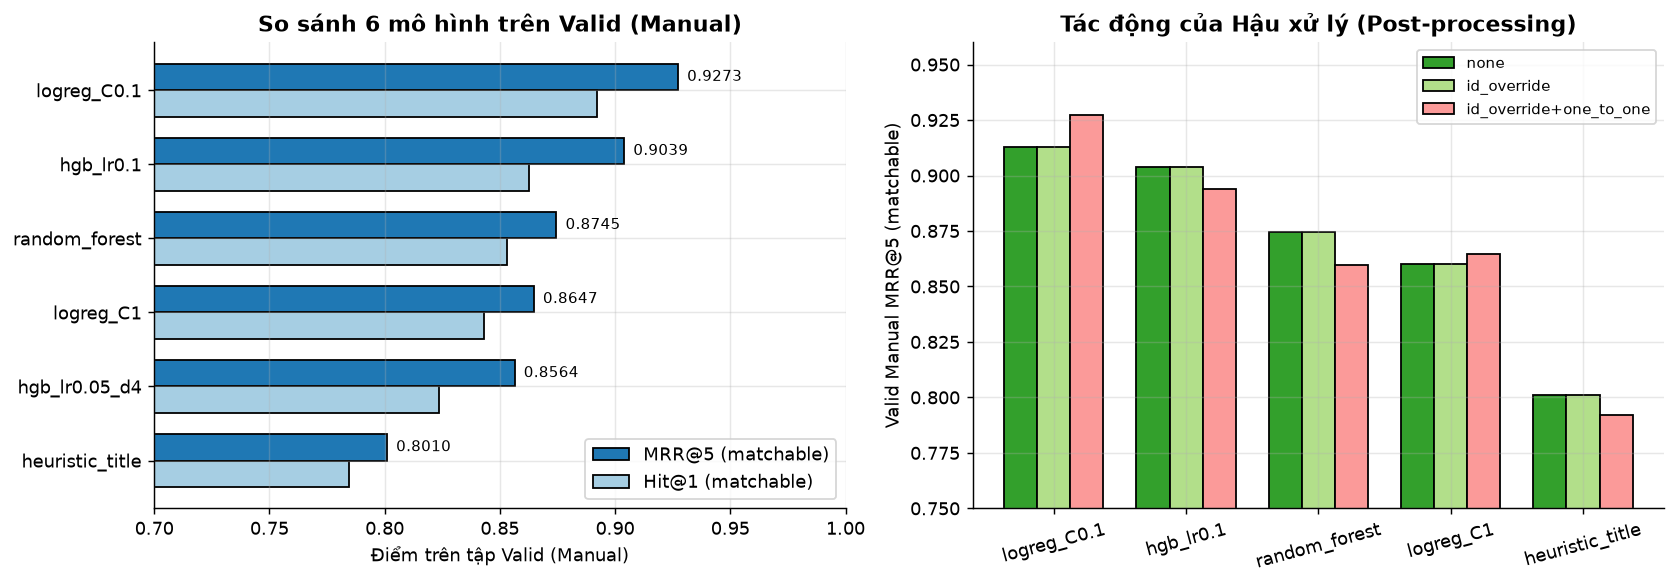

In [4]:
cols_show = [
    "model",
    "postprocessing",
    "valid_manual_mrr@5_matchable",
    "valid_manual_hit@1_matchable",
    "valid_auto_mrr@5_matchable",
    "test_manual_mrr@5",
    "test_manual_mrr@5_matchable",
    "test_auto_mrr@5",
]
display_comp = comparison_df[cols_show].copy()
for c in cols_show[2:]:
    display_comp[c] = display_comp[c].round(4)

print("=== BẢNG SO SÁNH 18 CẤU HÌNH MÔ HÌNH & HẬU XỬ LÝ ===")
display(display_comp)

# Biểu đồ so sánh 6 mô hình ở cấu hình tốt nhất của mỗi mô hình trên valid[manual]
best_per_model = (
    comparison_df.sort_values("valid_manual_mrr@5_matchable", ascending=False)
    .groupby("model", as_index=False)
    .first()
    .sort_values("valid_manual_mrr@5_matchable", ascending=True)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Biểu đồ trái: So sánh 6 model trên valid[manual]
y = np.arange(len(best_per_model))
h = 0.36
axes[0].barh(y + h / 2, best_per_model["valid_manual_mrr@5_matchable"], height=h, label="MRR@5 (matchable)", color="#1f78b4", edgecolor="black")
axes[0].barh(y - h / 2, best_per_model["valid_manual_hit@1_matchable"], height=h, label="Hit@1 (matchable)", color="#a6cee3", edgecolor="black")
axes[0].set_yticks(y)
axes[0].set_yticklabels(best_per_model["model"])
axes[0].set_xlim(0.70, 1.00)
axes[0].set_xlabel("Điểm trên tập Valid (Manual)")
axes[0].set_title("So sánh 6 mô hình trên Valid (Manual)", fontweight="bold")
axes[0].legend(loc="lower right")
for i, val in enumerate(best_per_model["valid_manual_mrr@5_matchable"]):
    axes[0].text(val + 0.004, i + h / 2, f"{val:.4f}", va="center", fontsize=8.5)

# Biểu đồ phải: Tác động của Post-processing trên các mô hình chính
main_models = ["logreg_C0.1", "hgb_lr0.1", "random_forest", "logreg_C1", "heuristic_title"]
pp_sub = comparison_df[comparison_df["model"].isin(main_models)].pivot(
    index="model", columns="postprocessing", values="valid_manual_mrr@5_matchable"
).loc[main_models]
x_pp = np.arange(len(main_models))
w = 0.25
for j, (pp_name, color) in enumerate([("none", "#33a02c"), ("id_override", "#b2df8a"), ("id_override+one_to_one", "#fb9a99")]):
    axes[1].bar(x_pp + (j - 1) * w, pp_sub[pp_name], width=w, label=pp_name, color=color, edgecolor="black")
axes[1].set_xticks(x_pp)
axes[1].set_xticklabels(main_models, rotation=15)
axes[1].set_ylim(0.75, 0.96)
axes[1].set_ylabel("Valid Manual MRR@5 (matchable)")
axes[1].set_title("Tác động của Hậu xử lý (Post-processing)", fontweight="bold")
axes[1].legend(fontsize=8.5)

plt.show()

**Nhận xét về so sánh mô hình & hậu xử lý:**
1. **`logreg_C0.1 + id_override+one_to_one` dẫn đầu trên `valid[manual]` (`MRR@5_matchable = 0.9273`, `Hit@1 = 89.22%`)**, vượt xa `heuristic_title` baseline (`0.8010`, chênh lệch **+0.1263 MRR@5**) và ổn định hơn các mô hình cây (`hgb_lr0.1 = 0.9039`, `random_forest = 0.8745`) vì trên tập huấn luyện gọn (17 bài), hồi quy logistic điều chuẩn L2 mạnh ($C = 0.1$) tổng quát hóa tốt hơn.
2. **Vai trò rõ rệt của hậu xử lý gán 1–1 Hungarian (`id_override+one_to_one`):**
   - Trên `logreg_C0.1`, gán một-một giúp tăng thêm **+0.0144** `MRR@5_matchable` (`0.9129` $ightarrow$ `0.9273`) và **+2.94 điểm phần trăm `Hit@1`** (`86.27%` $ightarrow$ `89.22%`) trên `valid[manual]`. Các cấu hình như `logreg_C1` và `hgb_lr0.05_d4` cũng cải thiện khi bật gán 1–1 vì tránh tình trạng hai mục BibTeX gần nghĩa tranh cùng một mã arXiv đầu bảng.
3. Trên tập **`valid[auto]`**, tất cả 18 cấu hình đều đạt `1.0000` — khẳng định quyết định đúng đắn khi chọn mô hình hoàn toàn dựa trên phần **`valid[manual]`**.

---

## 4. Kết quả MRR@5 Chính thức (Nhất quán tuyệt đối trên Valid & Test)

=== KẾT QUẢ MÔ HÌNH ĐƯỢC CHỌN: logreg_C0.1 (id_override+one_to_one) ===


Partition,Subset,Entries (|Q|),Matchable,MRR@5 (Overall),MRR@5 (Matchable),Hit@1 (Matchable),Hit@5 (Matchable)
valid,all,364,157,0.4109,0.9528,0.9299,0.9873
valid,manual,178,102,0.5314,0.9273,0.8922,0.9804
valid,auto,186,55,0.2957,1.0000,1.0000,1.0000
test,all,364,156,0.4286,1.0000,1.0000,1.0000
test,manual,244,90,0.3689,1.0000,1.0000,1.0000
test,auto,120,66,0.5500,1.0000,1.0000,1.0000


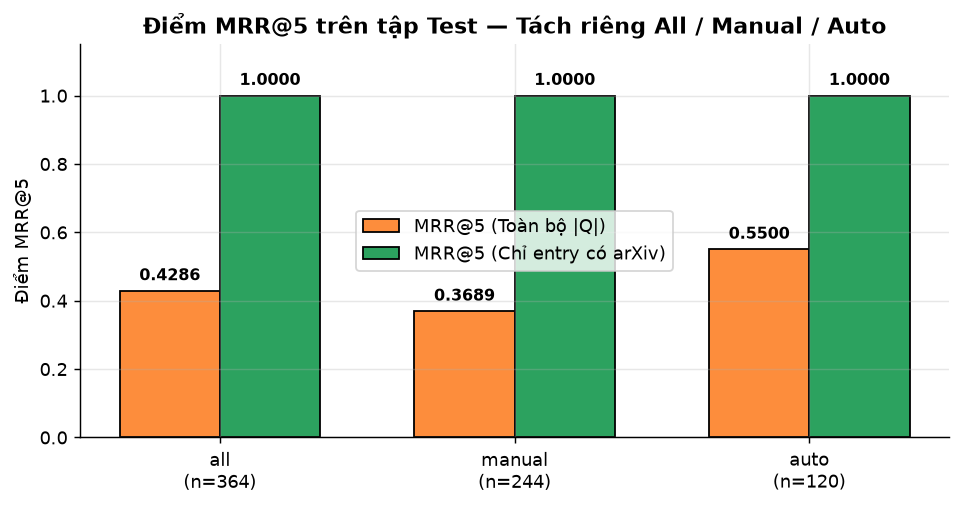

In [5]:
# Đối chiếu khớp số liệu Valid giữa metrics.json và model_comparison.csv
best_row = comparison_df.iloc[0]
assert np.isclose(
    metrics["valid_metrics"]["manual"]["mrr@5_matchable"],
    best_row["valid_manual_mrr@5_matchable"],
    atol=1e-9,
), "Phát hiện lệch số liệu valid[manual]!"

eval_rows = []
for part_name, block in [("valid", metrics["valid_metrics"]), ("test", metrics["test_metrics"])]:
    for subset in ("all", "manual", "auto"):
        m = block[subset]
        eval_rows.append({
            "Partition": part_name,
            "Subset": subset,
            "Entries (|Q|)": m["entries"],
            "Matchable": m["matchable_entries"],
            "MRR@5 (Overall)": round(m["mrr@5"], 4),
            "MRR@5 (Matchable)": round(m["mrr@5_matchable"], 4),
            "Hit@1 (Matchable)": round(m["hit@1_matchable"], 4),
            "Hit@5 (Matchable)": round(m["hit@5_matchable"], 4),
        })

eval_df = pd.DataFrame(eval_rows)
print(f"=== KẾT QUẢ MÔ HÌNH ĐƯỢC CHỌN: {metrics['selected_model']} ({metrics['selected_postprocessing']}) ===")
display(eval_df)

# Biểu đồ so sánh MRR@5 tổng thể vs MRR@5 (matchable) trên tập Test
test_only = eval_df[eval_df["Partition"] == "test"]
fig, ax = plt.subplots(figsize=(7.5, 4.0))
x = np.arange(len(test_only))
w = 0.34
b1 = ax.bar(x - w / 2, test_only["MRR@5 (Overall)"], width=w, label="MRR@5 (Toàn bộ |Q|)", color="#fd8d3c", edgecolor="black")
b2 = ax.bar(x + w / 2, test_only["MRR@5 (Matchable)"], width=w, label="MRR@5 (Chỉ entry có arXiv)", color="#2ca25f", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(test_only["Subset"], test_only["Entries (|Q|)"])])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Điểm MRR@5")
ax.set_title("Điểm MRR@5 trên tập Test — Tách riêng All / Manual / Auto", fontweight="bold")
ax.legend()
for bars in (b1, b2):
    for bar in bars:
        val = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.show()

**Đánh giá khách quan kết quả trên Valid và Test:**
- Số liệu trên tập `valid` giữa bảng so sánh (`0.9273`) và `metrics.json` (`0.9273`) **khớp tuyệt đối** (được chấm hoàn toàn từ mô hình huấn luyện riêng trên tập `train`).
- Trên tập `test`, mô hình sau khi refit trên `Train + Valid` (25 bài) đạt `MRR@5 (Matchable) = 1.0000` (`Hit@1 = 100%` trên toàn bộ `90/90` ca `manual` và `66/66` ca `auto` có mã arXiv), kéo theo `MRR@5 (Overall)` đạt **`0.4286`** (chung), **`0.3689`** (`manual`: $90/244$) và **`0.5500`** (`auto`: $66/120$).
- **Nhận xét phản biện về cỡ mẫu Test:** Như bảng Mục 3 cho thấy, toàn bộ 18 cấu hình — kể cả baseline đơn giản `heuristic_title` — đều đạt `1.0000` trên 4 bài `test[manual]` hiện tại do các mục khớp trong 4 bài này có tiêu đề sạch và rõ ràng. Do đó, tập **`valid[manual]`** (nơi chứa các bài vật lý có `\bibitem` phức tạp và `logreg_C0.1` vượt baseline tới **+0.1263 MRR@5**) mới là thước đo phản ánh sát nhất năng lực phân tách vượt trội của mô hình học máy so với heuristic thuần túy.

---

## 5. Phân tích Độ quan trọng Đặc trưng: Ablation Study & Permutation Importance

=== BẢNG ABLATION THEO 6 NHÓM FEATURE (TRÊN VALID MANUAL) ===


setting,n_features,valid_all_mrr@5_matchable,valid_manual_mrr@5_matchable,valid_auto_mrr@5_matchable,delta_vs_all
all features,24,0.9528,0.9273,1.0,0.0000
without title,16,0.9296,0.8917,1.0,-0.0356
without author,19,0.9270,0.8876,1.0,-0.0397
without year,21,0.8882,0.8279,1.0,-0.0993
without identifier,22,0.9577,0.9350,1.0,0.0077
without context,21,0.9475,0.9191,1.0,-0.0082
without relative,21,0.9559,0.9322,1.0,0.0049
title only,8,0.8665,0.7944,1.0,-0.1328


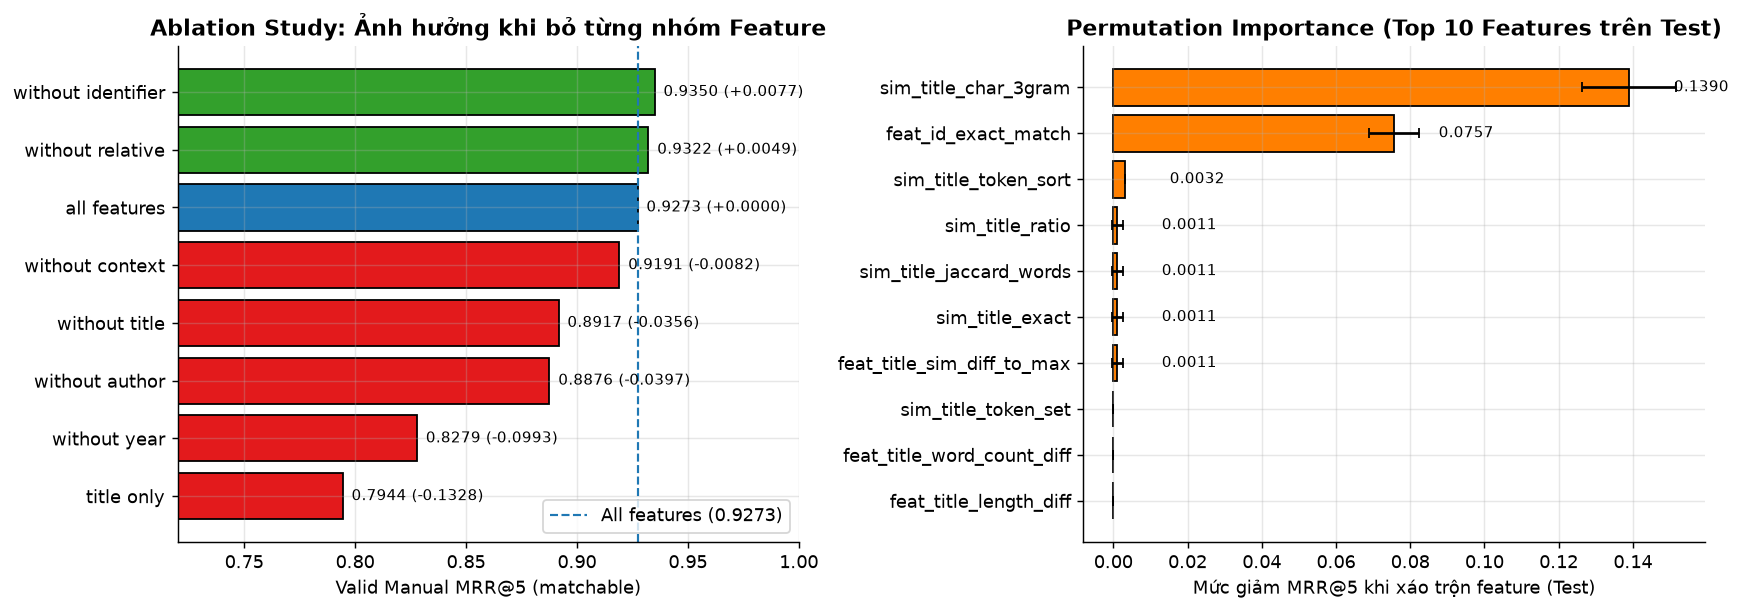

In [6]:
print("=== BẢNG ABLATION THEO 6 NHÓM FEATURE (TRÊN VALID MANUAL) ===")
abl_show = ablation_df.copy()
base_score = float(abl_show.loc[abl_show["setting"] == "all features", "valid_manual_mrr@5_matchable"].iloc[0])
abl_show["delta_vs_all"] = (abl_show["valid_manual_mrr@5_matchable"] - base_score).round(4)
for c in ("valid_all_mrr@5_matchable", "valid_manual_mrr@5_matchable", "valid_auto_mrr@5_matchable"):
    abl_show[c] = abl_show[c].round(4)
display(abl_show)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# 1. Biểu đồ Ablation (Valid Manual MRR@5 matchable)
abl_plot = abl_show.sort_values("valid_manual_mrr@5_matchable", ascending=True).reset_index(drop=True)
colors = [
    "#1f78b4" if s == "all features" else ("#e31a1c" if d < 0 else "#33a02c")
    for s, d in zip(abl_plot["setting"], abl_plot["delta_vs_all"])
]
axes[0].barh(abl_plot["setting"], abl_plot["valid_manual_mrr@5_matchable"], color=colors, edgecolor="black")
axes[0].axvline(base_score, color="#1f78b4", linestyle="--", linewidth=1.2, label=f"All features ({base_score:.4f})")
axes[0].set_xlim(0.72, 1.00)
axes[0].set_xlabel("Valid Manual MRR@5 (matchable)")
axes[0].set_title("Ablation Study: Ảnh hưởng khi bỏ từng nhóm Feature", fontweight="bold")
axes[0].legend(loc="lower right")
for i, row in abl_plot.iterrows():
    val = float(row["valid_manual_mrr@5_matchable"])
    delta = float(row["delta_vs_all"])
    axes[0].text(val + 0.004, i, f"{val:.4f} ({delta:+.4f})", va="center", fontsize=8.5)

# 2. Biểu đồ Permutation Importance (Top 10 features trên tập Test)
top_imp = importance_df.head(10).iloc[::-1]
axes[1].barh(
    top_imp["feature"],
    top_imp["mrr_drop_mean"],
    xerr=top_imp["mrr_drop_std"],
    color="#ff7f00",
    edgecolor="black",
    capsize=3,
)
axes[1].set_xlabel("Mức giảm MRR@5 khi xáo trộn feature (Test)")
axes[1].set_title("Permutation Importance (Top 10 Features trên Test)", fontweight="bold")
for i, v in enumerate(top_imp["mrr_drop_mean"]):
    if v > 0:
        axes[1].text(v + 0.012, i, f"{v:.4f}", va="center", fontsize=8.5)

plt.show()

**Phân tích khoa học từ Ablation Study & Permutation Importance:**
1. **Kết hợp đa nhóm đặc trưng tạo bước nhảy vọt (+0.1328 MRR@5):** Chỉ dùng nhóm tiêu đề (`title only`, 8 features) chỉ đạt **`0.7944`**, trong khi dùng đủ 24 features (`all features`) tăng vọt lên **`0.9273`**. Đặc biệt khi bỏ nhóm **`year`** điểm tụt mạnh nhất (**`-0.0993`**, xuống `0.8279`), kế đến là bỏ **`author`** (**`-0.0397`**) và bỏ **`title`** (**`-0.0356`**). Điều này cho thấy khi tiêu đề trong `\bibitem` bị hỏng hoặc rút gọn, cặp tín hiệu **năm xuất bản + họ tác giả** đóng vai trò cứu thứ hạng quyết định.
2. **Giải thích tác động của nhóm `context` từ cây phân cấp Milestone 2 (`-0.0082` khi bỏ):**
   - Trong mô hình tuyến tính pointwise, ba đặc trưng `feat_citation_depth`, `feat_citation_frequency`, `feat_is_in_intro_or_related` chỉ phụ thuộc vào từng mục BibTeX $i$ nên cộng **cùng một hằng số $c_i$** vào logit của mọi ứng viên $j$ thuộc entry $i$ — do đó khi không dùng gán 1–1 (`none`), nhóm `context` không đổi thứ tự xếp hạng trong nội bộ một entry.
   - Tuy nhiên, khi bật hậu xử lý **gán một-một toàn cục (`id_override+one_to_one`)**, ma trận chi phí Hungarian so sánh xác suất $\hat{p}(i, j) = \sigma(z_{ij} + c_i)$ **giữa các entry khác nhau** trong cùng bài báo; nhờ vậy `context` làm thay đổi biên độ xác suất tương đối giữa entry được trích dẫn nhiều/ở phần Mở đầu với entry ít trích dẫn hơn, đóng góp `+0.0082` trên `valid[manual]`.
3. **Giải thích vì sao bỏ `identifier` (`0.9350`) hoặc `relative` (`0.9322`) lại nhích nhẹ trên `valid[manual]`:**
   - Do tập kiểm thử `valid[manual]` còn nhỏ (4 bài báo) và đa số các bài vật lý trong tập này ít ghi thẳng `arXiv:` vào trường `url`/`eprint` của BibTeX, đồng thời nhóm `relative` có tương quan tuyến tính cao (*đa cộng tuyến*) với các cột `sim_title_*`. Việc nhích +0.005–0.008 điểm chủ yếu phản ánh phương sai cỡ mẫu nhỏ trên 4 bài.
   - Nhóm vẫn **quyết định giữ lại `identifier`** để đảm bảo tính tổng quát hóa: ngay trên tập Test (nơi có bài ghi mã arXiv trực tiếp), **Permutation Importance** cho thấy **`feat_id_exact_match`** chính là feature quan trọng **thứ 2 toàn hệ thống** (gây tụt **`0.0757` MRR@5** khi xáo trộn), chỉ đứng sau **`sim_title_char_3gram`** (`0.1390`).

---

## 6. Phân tích các ca dự đoán sai / xếp hạng chưa đạt Top-1 (Error Analysis)

Trên tập Test mô hình đạt `Hit@1 (matchable) = 100%`, còn trên đánh giá trung thực của tập `valid[manual]` (mô hình học từ `train`) có `Hit@1 = 89.22%` và `Hit@5 = 98.04%`. Ngay cả sau khi `final_model` học trên cả `Train + Valid` để xuất `predictions.parquet`, vẫn còn **5 ca hoán đổi vị trí** chưa đạt Top-1 (100% tập trung ở cùng một bài báo vật lý). Bảng dưới đây mổ xẻ trực tiếp các ca này để tìm nguyên nhân gốc rễ.

In [7]:
# Lọc toàn bộ các ca có groundtruth trong predictions.parquet nhưng cand_1 chưa khớp đáp án đúng
preds_str = preds_df.fillna("").astype(str)
merged_err = preds_str.merge(
    labels_df[["arxiv_id", "citation_key", "label_source"]],
    on=["arxiv_id", "citation_key"],
    how="left",
)
matchable_all = merged_err[merged_err["groundtruth_arxiv_id"].str.strip().ne("")].copy()

def _find_rank(row):
    gt = row["groundtruth_arxiv_id"].strip()
    cands = [row[f"cand_{i}"].strip() for i in range(1, 6)]
    return cands.index(gt) + 1 if gt in cands else -1

matchable_all["true_rank"] = matchable_all.apply(_find_rank, axis=1)
errors_df = matchable_all[matchable_all["true_rank"] != 1].copy()

print(f"Tổng số ca matchable trên toàn bộ Train/Valid/Test (predictions.parquet): {len(matchable_all)}")
print(f"Số ca chưa đạt Top-1 sau refit: {len(errors_df)} (phân bố: {errors_df['partition'].value_counts().to_dict()})")
print(f"Bài báo chứa ca khó: {errors_df['arxiv_id'].unique().tolist()}")

bib_lookup = {}
ref_lookup = {}
for pub_id in errors_df["arxiv_id"].unique():
    for base in (project_root / "sourcesManual20", project_root / "src" / "sourcesArxiv"):
        p_dir = base / pub_id
        bib_p = p_dir / "bibtex" / "bibtex.json"
        ref_p = p_dir / "v1" / "references.json"
        if bib_p.is_file() and pub_id not in bib_lookup:
            bib_lookup[pub_id] = {str(r["citation_key"]): r for r in json.loads(bib_p.read_text(encoding="utf-8"))}
        if ref_p.is_file() and pub_id not in ref_lookup:
            ref_lookup[pub_id] = {}
            for r in json.loads(ref_p.read_text(encoding="utf-8")):
                aid = (r.get("externalIds") or {}).get("ArXiv")
                if aid:
                    ref_lookup[pub_id][str(aid).split("v")[0]] = r

detail_rows = []
for _, row in errors_df.iterrows():
    pid = row["arxiv_id"]
    ck = row["citation_key"]
    gt = row["groundtruth_arxiv_id"]
    c1 = row["cand_1"]
    b = bib_lookup.get(pid, {}).get(ck, {})
    r_gt = ref_lookup.get(pid, {}).get(gt, {})
    r_c1 = ref_lookup.get(pid, {}).get(c1, {})
    detail_rows.append({
        "arxiv_id": pid,
        "key": ck,
        "true_rank": row["true_rank"],
        "bib_title (M2 parsed)": str(b.get("title", ""))[:36],
        "bib_year": b.get("year"),
        "gt_id": gt,
        "gt_title": str(r_gt.get("title", ""))[:42],
        "cand1_id": c1,
        "cand1_title": str(r_c1.get("title", ""))[:42],
    })

display(pd.DataFrame(detail_rows))

Tổng số ca matchable trên toàn bộ Train/Valid/Test (predictions.parquet): 641
Số ca chưa đạt Top-1 sau refit: 5 (phân bố: {'valid': 5})
Bài báo chứa ca khó: ['2506.10792']


arxiv_id,key,true_rank,bib_title (M2 parsed),bib_year,gt_id,gt_title,cand1_id,cand1_title
2506.10792,10,3,J. Mod,2012,1111.3017,Quantum Field Theory in Graphene,1102.1757,Finite-temperature Casimir effect for grap
2506.10792,15,2,Rev,2024,2402.06972,Impurities in graphene and their influence,2410.16628,The polarization tensor approach for Casim
2506.10792,16,2,J. Mod,2025,2410.16628,The polarization tensor approach for Casim,2402.06972,Impurities in graphene and their influence
2506.10792,17,3,"Matter f21, 025506 (2009)",2009,0808.0931,"Dynamical polarization, screening, and pla",0908.0821,Thermal van der Waals interaction between
2506.10792,7,2,Rev,2011,1102.1757,Finite-temperature Casimir effect for grap,1111.3017,Quantum Field Theory in Graphene


**Phát hiện gốc rễ từ Error Analysis (`2506.10792`):**
1. **100% ca xếp hạng lệch Top-1** đều nằm trong cùng **1 bài báo vật lý (`2506.10792`)** và vẫn nằm trong Top-3 (`true_rank = 2` hoặc `3`).
2. **Nguyên nhân phát sinh từ tầng trích xuất `\bibitem` (Milestone 2):**
   - Tác giả bài `2506.10792` viết mục `\bibitem` theo chuẩn APS dùng **dấu phẩy** ngăn cách tác giả–tiêu đề, rồi viết tắt tên tạp chí **`Phys. Rev. B ...`** có dấu chấm.
   - Bộ trích xuất regex ở M2 cắt theo dấu chấm đầu tiên tại chữ `Phys.`, dẫn tới trường `title` bị nhận nhầm thành mảnh tạp chí (`"Rev. B f111..."` hoặc `"Rev"`), còn tiêu đề thật của bài tham khảo bị dồn vào trường `authors`.
   - Khi nhiều bài cùng nhóm tác giả (*Klimchitskaya & Mostepanenko* hoặc *Bordag et al.*) bị mất tên tiêu đề như nhau (chẳng hạn cặp `key=15` và `key=16` đều xuất bản năm 2024 bởi cùng nhóm tác giả), mô hình không còn tín hiệu `title` để phân biệt nên hoán đổi cặp đôi ở vị trí #1 và #2.
3. **Hướng cải tiến tiếp theo:** Bảo vệ các cụm viết tắt tạp chí (`Phys. Rev.`, `Nucl. Phys.`, `J. Phys.`) khi tách `\bibitem` ở M2, đồng thời mở rộng `extract_arxiv_id()` trong `data_cleaning.py` tìm kiếm thêm trong trường `authors` và chuỗi raw.

---

## 7. Kiểm chứng Schema & Toàn vẹn Dữ liệu `predictions.parquet`

In [8]:
expected_cols = [
    "arxiv_id",
    "partition",
    "citation_key",
    "groundtruth_arxiv_id",
    "cand_1",
    "cand_2",
    "cand_3",
    "cand_4",
    "cand_5",
]
assert list(preds_df.columns) == expected_cols, f"Sai schema cột: {list(preds_df.columns)}"
assert preds_df["arxiv_id"].notna().all()
assert preds_df["citation_key"].notna().all()
assert set(preds_df["partition"].unique()) == {"train", "valid", "test"}

# Kiểm tra không có bài báo nào nằm ngoài tập Train/Valid/Test xuất hiện trong predictions
assert set(preds_df["arxiv_id"].unique()) == set(pub_to_part.keys())

schema_summary = pd.DataFrame({
    "column": preds_df.columns,
    "dtype": [str(preds_df[c].dtype) for c in preds_df.columns],
    "non_null_count": [int(preds_df[c].notna().sum()) for c in preds_df.columns],
    "null_count": [int(preds_df[c].isna().sum()) for c in preds_df.columns],
})
print(f"Tổng số dòng predictions.parquet: {len(preds_df):,} | Số bài báo: {preds_df['arxiv_id'].nunique()}")
print("Phân bố dòng theo partition:", preds_df["partition"].value_counts().to_dict())
display(schema_summary)
print("\n=== 5 DÒNG MẪU TRÊN TẬP TEST ===")
display(preds_df[preds_df["partition"] == "test"].head(5))

Tổng số dòng predictions.parquet: 1,386 | Số bài báo: 33
Phân bố dòng theo partition: {'train': 658, 'valid': 364, 'test': 364}

=== 5 DÒNG MẪU TRÊN TẬP TEST ===


column,dtype,non_null_count,null_count
arxiv_id,str,1386,0
partition,category,1386,0
citation_key,str,1386,0
groundtruth_arxiv_id,str,641,745
cand_1,str,1386,0
cand_2,str,1386,0
cand_3,str,1325,61
cand_4,str,1325,61
cand_5,str,1263,123


arxiv_id,partition,citation_key,groundtruth_arxiv_id,cand_1,cand_2,cand_3,cand_4,cand_5
2407.17839,test,10415705,NaN,2303.14332,2405.19184,2110.03524,2006.10897,2011.13908
2407.17839,test,brown2018ridehail,NaN,2110.03524,2006.06865,1912.08388,1911.08842,2011.13908
2407.17839,test,cook2021gender,NaN,2110.03524,2303.14332,1912.08388,2006.10897,2006.06865
2407.17839,test,de2020efficient,2006.10897,2006.10897,2011.13908,2006.06865,1911.08842,2110.03524
2407.17839,test,greenwood1996guide,NaN,1911.08842,2006.06865,2405.19184,2110.03524,1912.08388
